# 05 · Modelos de redes complexas

**Objetivo:** comparar a rede sintética de Pix com modelos clássicos de redes aleatórias. Isso ajuda a entender quais propriedades são "normais" numa rede de transações e quais seriam anômalas.

**Conceitos:** distribuição de graus, cauda pesada, lei de potência, agrupamento médio, distância média, mundo pequeno, modelo nulo.

**Leitura de apoio:** Easley & Kleinberg, cap. 18 (leis de potência e "os ricos ficam mais ricos") e cap. 20 (o fenômeno do mundo pequeno).

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from pixfraud.graph import build_graph
from pixfraud.simulation import load_dataset

## 1. Os modelos

| Modelo | Como é gerado | Propriedade marcante |
|---|---|---|
| **Erdős–Rényi** $G(n, m)$ | $m$ arestas sorteadas ao acaso entre $n$ vértices | graus concentrados em torno da média (Poisson); pouco agrupamento |
| **Barabási–Albert** | cada vértice novo se liga a $m$ vértices, com preferência pelos de grau alto | **cauda pesada**: poucos hubs com grau enorme ("os ricos ficam mais ricos") |
| **Watts–Strogatz** | anel em que cada vértice se liga aos $k$ vizinhos mais próximos; cada aresta é religada ao acaso com probabilidade $p$ | **mundo pequeno**: agrupamento alto e distâncias curtas |

Para comparar com justiça, os modelos são gerados com o mesmo número de vértices e aproximadamente o mesmo número de arestas da rede Pix (na versão não direcionada).

In [2]:
contas, tx = load_dataset("../data/synthetic")
pix = nx.Graph(build_graph(tx).to_undirected())
n, m = pix.number_of_nodes(), pix.number_of_edges()
k = round(2 * m / n)  # grau médio
print(f"n = {n}, m = {m}, grau médio ≈ {k}")

modelos = {
    "Pix sintético": pix,
    "Erdős–Rényi": nx.gnm_random_graph(n, m, seed=1),
    "Barabási–Albert": nx.barabasi_albert_graph(n, k // 2, seed=1),
    "Watts–Strogatz": nx.watts_strogatz_graph(n, k + k % 2, 0.1, seed=1),
}

n = 2142, m = 29830, grau médio ≈ 28


## 2. Comparando propriedades

A distância média entre todos os pares é cara de calcular, então estimamos a partir de uma amostra de 200 vértices de origem, dentro da maior componente.

In [3]:
def distancia_media(G, amostra=200, seed=0):
    maior = G.subgraph(max(nx.connected_components(G), key=len))
    rng = np.random.default_rng(seed)
    nos = list(maior)
    origens = [nos[i] for i in rng.choice(len(nos), size=min(amostra, len(nos)), replace=False)]
    soma = pares = 0
    for s in origens:
        distancias = nx.single_source_shortest_path_length(maior, s)
        soma += sum(distancias.values())
        pares += len(distancias) - 1
    return soma / pares


linhas = []
for nome, G in modelos.items():
    graus = np.array([d for _, d in G.degree()])
    linhas.append({
        "modelo": nome,
        "arestas": G.number_of_edges(),
        "grau médio": graus.mean(),
        "grau máximo": graus.max(),
        "desvio do grau": graus.std(),
        "agrupamento médio": nx.average_clustering(G),
        "distância média": distancia_media(G),
    })
pd.DataFrame(linhas).set_index("modelo").round(3)

,arestas,grau médio,grau máximo,desvio do grau,agrupamento médio,distância média
modelo,,,,,,
Pix sintético,29830,27.852,1573,52.119,0.254,2.233
Erdős–Rényi,29830,27.852,48,5.368,0.013,2.672
Barabási–Albert,29792,27.817,278,25.521,0.043,2.579
Watts–Strogatz,29988,28.000,34,1.644,0.530,3.174


## 3. Distribuição de graus

A curva abaixo é a **distribuição acumulada complementar**: para cada grau $k$, a fração de vértices com grau $\geq k$. Em escala log-log, uma lei de potência $P(\text{grau} \geq k) \propto k^{-\gamma}$ vira uma reta. A Poisson do Erdős–Rényi cai abruptamente.

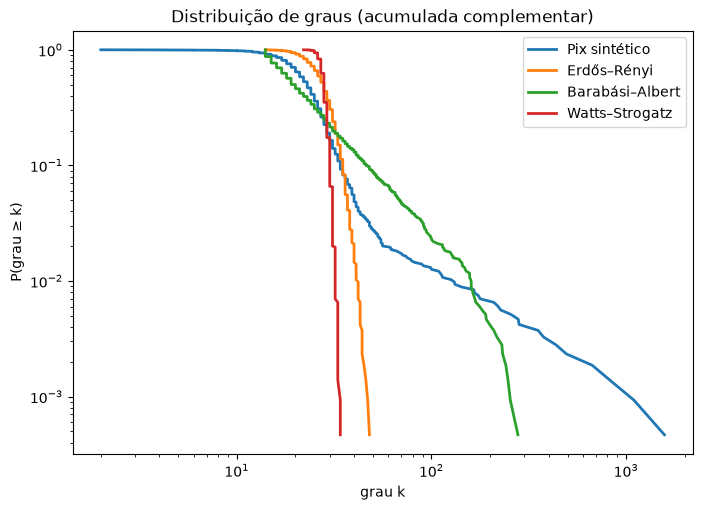

In [4]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for nome, G in modelos.items():
    graus = np.sort([d for _, d in G.degree() if d > 0])
    ccdf = 1 - np.arange(len(graus)) / len(graus)
    ax.loglog(graus, ccdf, label=nome, lw=2)
ax.set_xlabel("grau k")
ax.set_ylabel("P(grau ≥ k)")
ax.legend()
ax.set_title("Distribuição de graus (acumulada complementar)");

**Interpretação:**

- O **agrupamento** da rede Pix sintética é bem maior que o do Erdős–Rényi. Isso vem dos círculos de contatos (parâmetro `community_size` do gerador), a mesma ideia do Watts–Strogatz.
- A **cauda** da distribuição de graus vem dos comércios, que recebem de muita gente, como os hubs do Barabási–Albert.
- A **distância média** é curta em todos os modelos: é o efeito "mundo pequeno".

Essas propriedades vêm das escolhas do gerador sintético, e não de dados reais. Validar se uma rede Pix real teria algo parecido é parte da etapa de análise exploratória.

## 4. Modelos nulos

Para dizer que uma estrutura é **anômala**, é preciso compará-la com o que se esperaria **por acaso**. Um **modelo nulo** é uma rede aleatória que preserva algumas propriedades da rede real e embaralha o resto. O mais usado é o **modelo de configuração**, que mantém exatamente o grau de cada vértice e sorteia as ligações.

Se a rede real tem muito mais triângulos que o modelo nulo, os triângulos não são consequência só dos graus: existe uma estrutura de comunidades. A mesma lógica vale para padrões de fraude: "esta conta tem muitos caminhos passando por ela, mais do que o esperado para o grau que ela tem?".

In [5]:
nulo = nx.Graph(nx.configuration_model([d for _, d in pix.degree()], seed=1))
nulo.remove_edges_from(nx.selfloop_edges(nulo))
print(f"agrupamento médio: Pix = {nx.average_clustering(pix):.3f} | modelo de configuração = {nx.average_clustering(nulo):.3f}")

agrupamento médio: Pix = 0.254 | modelo de configuração = 0.076


## Exercícios

1. **Barabási–Albert.** Gere redes BA com $n = 1000$ e $m = 1, 2, 5$. Compare o grau máximo e desenhe as três distribuições acumuladas no mesmo gráfico.
2. **Mundo pequeno.** Gere redes Watts–Strogatz com $n = 1000$, $k = 10$ e $p = 0, 0{,}01, 0{,}1, 1$. Monte uma tabela com agrupamento médio e distância média. Para qual $p$ a rede já tem distâncias curtas mas ainda mantém agrupamento alto?
3. **Hubs.** Na rede Pix sintética, quais são as 10 contas de maior grau? Que papéis elas têm? O que acontece com a distância média se você remover essas contas?

In [6]:
# seu código aqui